# Лабораторна робота № 2

## Оптимізаційна задача та аналіз чутливості

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Побудувати оптимізаційну модель у двох середовищах, прочитати звіт про стійкість
і **ухвалити на його основі господарське рішення**.

Розв'язати задачу — не мета. Solver зробить це за дві секунди. Робота оцінюється за
те, що ви зумієте зі звіту витягнути.

### Дві частини

| Частина | Задача | Де виконується |
|---|---|---|
| **1** | виробнича задача — Excel і Python | аудиторно |
| **2** | транспортна задача — Python | самостійно |

Друга частина потрібна не для повторення. Там та сама методика поводиться інакше,
і ви маєте побачити, де саме проходить межа її застосовності.

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Виконується згори донизу на чистому
   ядрі** (Kernel → Restart & Run All) без помилок — перевіряється першою дією на захисті.
2. Файл Excel з моделлю, налаштуваннями Solver і **звітом про стійкість** окремим аркушем.
3. Заповнена декларація про використання ШІ (етап 12).

### Оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Модель не сформульовано або розв'язок не отримано |
| 1 | Розв'язок отримано лише в одному середовищі, звіт про стійкість не проаналізовано |
| 2 | Задачу розв'язано в обох середовищах і звіти зіставлено, але тіньові ціни та діапазони не інтерпретовано |
| 4 | Звіт прочитано й перевірено експериментом, ухвалено обґрунтоване рішення про закупівлю, виконано частину 2 з поясненням розбіжності |

---
## Крок 0. Ваші дані та варіант

In [1]:
ПІБ = 'Цимбалюк Антон Едуардович'
ГРУПА = 'ШІ-34'
ВАРІАНТ = 15

assert ПІБ and ГРУПА and 1 <= ВАРІАНТ <= 30, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ (1..30)'

In [2]:
# --- клітинку не редагувати: вона видає дані вашого варіанта -----------------
import json, numpy as np, pandas as pd

ДАНІ_ВАРІАНТІВ = json.loads('''{"1": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[0, 2, 1, 1], [3, 3, 0, 6], [2, 3, 0, 2], [4, 6, 0, 5], [3, 1, 5, 4]], "c": [21, 69, 44, 39], "b": [929, 410, 507, 865, 425], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.2, "обсяг_пропозиції": 44}, "2": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 2, 5, 2], [6, 5, 4, 2], [5, 2, 0, 3], [2, 1, 5, 0], [5, 5, 6, 2]], "c": [40, 66, 24, 34], "b": [1271, 702, 915, 1388, 804], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.7, "обсяг_пропозиції": 204}, "3": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 2, 6, 6], [3, 4, 3, 6], [1, 6, 6, 0], [3, 1, 6, 1], [4, 1, 1, 4]], "c": [51, 16, 34, 22], "b": [1189, 686, 1311, 512, 1030], "ресурс_пропозиції": 3, "ціна_пропозиції": 11.3, "обсяг_пропозиції": 348}, "4": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 0, 0, 0], [1, 0, 5, 2], [2, 4, 6, 5], [3, 0, 5, 3], [2, 1, 2, 5]], "c": [41, 50, 54, 26], "b": [815, 344, 840, 840, 382], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.3, "обсяг_пропозиції": 144}, "5": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 0, 6, 6], [3, 2, 2, 4], [5, 5, 0, 6], [2, 1, 5, 3], [5, 5, 4, 2]], "c": [32, 66, 25, 24], "b": [874, 1034, 1349, 845, 1394], "ресурс_пропозиції": 2, "ціна_пропозиції": 8.6, "обсяг_пропозиції": 90}, "6": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[3, 2, 1, 4], [4, 2, 2, 1], [3, 5, 1, 2], [3, 2, 0, 2], [6, 4, 6, 3]], "c": [40, 62, 19, 57], "b": [630, 391, 1349, 811, 1085], "ресурс_пропозиції": 1, "ціна_пропозиції": 29.5, "обсяг_пропозиції": 268}, "7": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[0, 0, 5, 5], [4, 4, 0, 1], [2, 4, 0, 6], [6, 3, 4, 1], [2, 2, 1, 0]], "c": [20, 59, 63, 41], "b": [1189, 1189, 1217, 915, 424], "ресурс_пропозиції": 3, "ціна_пропозиції": 8.0, "обсяг_пропозиції": 314}, "8": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[2, 1, 3, 5], [3, 1, 0, 6], [1, 6, 1, 5], [2, 2, 4, 0], [6, 1, 2, 2]], "c": [60, 25, 59, 25], "b": [1279, 761, 376, 1230, 1065], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.5, "обсяг_пропозиції": 234}, "9": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 2, 1, 2], [5, 0, 1, 3], [5, 4, 6, 4], [4, 1, 1, 5], [6, 0, 3, 0]], "c": [58, 39, 54, 16], "b": [1147, 1199, 1280, 404, 1170], "ресурс_пропозиції": 2, "ціна_пропозиції": 6.1, "обсяг_пропозиції": 672}, "10": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 0, 4, 3], [0, 6, 0, 6], [5, 5, 3, 5], [6, 2, 3, 3], [3, 0, 0, 4]], "c": [20, 29, 37, 63], "b": [905, 344, 866, 1390, 355], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.3, "обсяг_пропозиції": 78}, "11": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 3], [3, 1, 4, 0], [1, 0, 3, 2], [3, 2, 2, 6], [3, 6, 0, 3]], "c": [30, 16, 51, 35], "b": [1312, 838, 1062, 1038, 1236], "ресурс_пропозиції": 1, "ціна_пропозиції": 15.6, "обсяг_пропозиції": 778}, "12": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 2, 0, 5], [1, 1, 3, 6], [6, 3, 5, 4], [2, 4, 6, 0], [4, 6, 2, 4]], "c": [39, 55, 36, 26], "b": [788, 661, 458, 1005, 535], "ресурс_пропозиції": 4, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 762}, "13": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[1, 5, 3, 0], [6, 4, 6, 3], [4, 4, 4, 1], [0, 3, 5, 3], [3, 5, 3, 3]], "c": [59, 42, 53, 19], "b": [937, 1390, 603, 1120, 1334], "ресурс_пропозиції": 2, "ціна_пропозиції": 15.1, "обсяг_пропозиції": 646}, "14": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 3, 3, 4], [6, 6, 1, 6], [1, 3, 5, 1], [1, 5, 1, 4], [4, 4, 0, 3]], "c": [26, 56, 41, 40], "b": [969, 672, 1364, 878, 618], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 222}, "15": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 3, 3, 1], [2, 5, 6, 6], [3, 1, 0, 0], [0, 4, 4, 6], [2, 2, 2, 6]], "c": [64, 58, 34, 63], "b": [613, 316, 1035, 739, 810], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.4, "обсяг_пропозиції": 354}, "16": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[1, 6, 4, 2], [4, 1, 1, 2], [4, 4, 6, 6], [5, 6, 3, 3], [1, 2, 4, 2]], "c": [33, 40, 58, 17], "b": [412, 1005, 996, 599, 390], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.2, "обсяг_пропозиції": 44}, "17": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[2, 6, 0, 3], [2, 5, 5, 3], [6, 0, 4, 5], [1, 3, 6, 2], [0, 1, 4, 4]], "c": [33, 52, 20, 66], "b": [989, 1079, 873, 1327, 1224], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.9, "обсяг_пропозиції": 402}, "18": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 3, 0, 1], [0, 6, 1, 6], [1, 0, 4, 1], [2, 6, 3, 4], [3, 1, 6, 5]], "c": [66, 54, 18, 66], "b": [1217, 668, 923, 1040, 619], "ресурс_пропозиції": 4, "ціна_пропозиції": 34.9, "обсяг_пропозиції": 100}, "19": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 2], [3, 3, 4, 5], [2, 1, 0, 4], [4, 1, 5, 0], [0, 3, 6, 3]], "c": [67, 52, 41, 40], "b": [315, 617, 815, 423, 1193], "ресурс_пропозиції": 1, "ціна_пропозиції": 9.3, "обсяг_пропозиції": 332}, "20": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 4, 5, 1], [2, 0, 5, 4], [4, 0, 2, 3], [3, 3, 4, 3], [4, 4, 5, 2]], "c": [42, 63, 35, 56], "b": [1191, 331, 685, 1275, 971], "ресурс_пропозиції": 4, "ціна_пропозиції": 12.2, "обсяг_пропозиції": 604}, "21": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 3, 6], [4, 4, 3, 2], [4, 4, 4, 0], [1, 1, 5, 3], [0, 2, 6, 5]], "c": [32, 66, 26, 64], "b": [464, 393, 354, 597, 887], "ресурс_пропозиції": 0, "ціна_пропозиції": 9.4, "обсяг_пропозиції": 190}, "22": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[6, 0, 2, 6], [3, 4, 0, 4], [4, 3, 1, 5], [5, 5, 6, 2], [2, 0, 1, 5]], "c": [65, 36, 50, 63], "b": [891, 1247, 613, 1070, 1259], "ресурс_пропозиції": 2, "ціна_пропозиції": 13.6, "обсяг_пропозиції": 64}, "23": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[1, 2, 4, 6], [4, 6, 2, 5], [0, 5, 3, 1], [0, 0, 5, 1], [5, 4, 0, 5]], "c": [15, 35, 49, 23], "b": [1251, 637, 304, 629, 923], "ресурс_пропозиції": 2, "ціна_пропозиції": 10.9, "обсяг_пропозиції": 146}, "24": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[3, 2, 6, 1], [0, 2, 5, 6], [2, 4, 4, 0], [5, 6, 2, 5], [2, 4, 2, 1]], "c": [45, 61, 59, 38], "b": [927, 1384, 1294, 798, 323], "ресурс_пропозиції": 4, "ціна_пропозиції": 20.5, "обсяг_пропозиції": 110}, "25": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 4, 4], [2, 1, 4, 1], [3, 1, 4, 4], [1, 4, 2, 0], [6, 4, 6, 6]], "c": [35, 27, 63, 61], "b": [1399, 843, 308, 1393, 713], "ресурс_пропозиції": 2, "ціна_пропозиції": 7.7, "обсяг_пропозиції": 334}, "26": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 1, 4, 4], [3, 1, 5, 0], [6, 3, 6, 3], [1, 3, 6, 1], [6, 4, 5, 2]], "c": [46, 57, 60, 39], "b": [513, 1330, 796, 406, 1258], "ресурс_пропозиції": 3, "ціна_пропозиції": 18.1, "обсяг_пропозиції": 448}, "27": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 6, 0], [6, 5, 6, 0], [5, 2, 3, 0], [6, 4, 3, 6], [6, 0, 0, 3]], "c": [24, 61, 50, 57], "b": [1179, 1358, 417, 463, 610], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.0, "обсяг_пропозиції": 742}, "28": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[4, 5, 6, 2], [6, 4, 2, 1], [0, 5, 4, 3], [6, 6, 3, 3], [4, 4, 4, 1]], "c": [37, 41, 30, 29], "b": [514, 461, 378, 834, 488], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.5, "обсяг_пропозиції": 174}, "29": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 5, 0, 5], [6, 0, 6, 1], [5, 2, 2, 3], [0, 3, 0, 1], [4, 5, 5, 0]], "c": [33, 57, 58, 62], "b": [820, 523, 670, 977, 1074], "ресурс_пропозиції": 0, "ціна_пропозиції": 15.2, "обсяг_пропозиції": 570}, "30": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 1, 4, 0], [6, 5, 1, 4], [5, 6, 1, 4], [1, 2, 6, 0], [1, 0, 3, 1]], "c": [51, 44, 69, 55], "b": [379, 620, 1256, 502, 414], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.9, "обсяг_пропозиції": 230}}''')

V = ДАНІ_ВАРІАНТІВ[str(ВАРІАНТ)]
A = np.array(V['A'], float)          # витрати ресурсу i на один виріб j
c = np.array(V['c'], float)          # прибуток з одного виробу
b = np.array(V['b'], float)          # запас ресурсу на плановий період
вироби, ресурси = V['вироби'], V['ресурси']

print('ВАРІАНТ %d · %s, %s, %s' % (ВАРІАНТ, ПІБ, ГРУПА, V['фірма']))
print('=' * 78)
print('Підприємство %s виготовляє %s. Одиниця виміру плану: %s.' % (V['фірма'], V['що'], V['од']))
print()
таб = pd.DataFrame(A, index=ресурси, columns=вироби).astype(int)
таб['ЗАПАС'] = b.astype(int)
print(таб.to_string())
print()
print(pd.DataFrame([c.astype(int)], index=['Прибуток з одиниці'], columns=вироби).to_string())
print()
print('ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)')
print('  ресурс: %s' % ресурси[V['ресурс_пропозиції']])
print('  ціна:   %.1f за одиницю' % V['ціна_пропозиції'])
print('  обсяг:  до %d одиниць' % V['обсяг_пропозиції'])

ВАРІАНТ 15 · Цимбалюк Антон Едуардович, ШІ-34, «Карпатський дуб»
Підприємство «Карпатський дуб» виготовляє меблі. Одиниця виміру плану: шт./тиждень.

                   Крісло  Стілець  Табурет  Лава  ЗАПАС
Дубовий брус, м         5        3        3     1    613
Фанера, м²              2        5        6     6    316
Фурнітура, компл.       3        1        0     0   1035
Верстат, год            0        4        4     6    739
Лакування, год          2        2        2     6    810

                    Крісло  Стілець  Табурет  Лава
Прибуток з одиниці      64       58       34    63

ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)
  ресурс: Дубовий брус, м
  ціна:   5.4 за одиницю
  обсяг:  до 354 одиниць


In [3]:
import matplotlib.pyplot as plt
try:
    import pulp
    ПУЛП = True
except ImportError:
    ПУЛП = False
    print('pulp не встановлено — скористайтеся scipy.optimize.linprog')
from scipy.optimize import linprog

pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

---
# ЧАСТИНА 1. Виробнича задача

# Етап 1. Формалізація

Перш ніж будувати таблицю, запишіть модель словами й формулами. Це найважливіші
двадцять хвилин роботи: помилку тут не виправить жодна кнопка.

### Завдання 1.1
Заповніть у клітинці нижче:

* **змінні рішення** — що саме ви обираєте і в яких одиницях;
* **цільова функція** — що робите найбільшим, з коефіцієнтами вашого варіанта;
* **обмеження** — по одному рядку на кожен ресурс, з числами вашого варіанта;
* **умови невід'ємності**.

Пишіть формулами, а не описом. Приклад запису одного обмеження:
`8·x1 + 4·x2 + 0·x3 + 2·x4 ≤ 1280   (конвеєр A)`

**Відповідь 1.1 — символічна модель** (варіант 15, «Карпатський дуб», меблі)

**Змінні рішення** (шт./тиждень):
$x_1$ — Крісло, $x_2$ — Стілець, $x_3$ — Табурет, $x_4$ — Лава.

**Цільова функція** (тижневий прибуток):

$$Z = 64x_1 + 58x_2 + 34x_3 + 63x_4 \;\to\; \max$$

**Обмеження** (по одному на ресурс):

| | | ресурс |
|---|---|---|
| $5x_1 + 3x_2 + 3x_3 + 1x_4 \le 613$ | | дубовий брус, м |
| $2x_1 + 5x_2 + 6x_3 + 6x_4 \le 316$ | | фанера, м² |
| $3x_1 + 1x_2 + 0x_3 + 0x_4 \le 1035$ | | фурнітура, компл. |
| $0x_1 + 4x_2 + 4x_3 + 6x_4 \le 739$ | | верстат, год |
| $2x_1 + 2x_2 + 2x_3 + 6x_4 \le 810$ | | лакування, год |

**Невід'ємність:** $x_1, x_2, x_3, x_4 \ge 0$.

У матричному вигляді: $\max\ c^\top x$ при $Ax \le b,\ x \ge 0$, де $A$ — матриця 5×4 норм витрат, $b$ — запаси, $c$ — прибуток з одиниці.

### Завдання 1.2 — питання на розуміння
Чому запас ресурсу — це **параметр**, а не змінна рішення? Що змінилося б у моделі,
якби підприємство могло докупити ресурс у будь-якій кількості?

**Відповідь 1.2:**

Змінна рішення — це те, що підприємство *обирає* в межах планового періоду (скільки виробів зробити). Запас ресурсу на цей період уже заданий ззовні: він лежить на складі або закріплений контрактом, і в межах тижня ми на нього не впливаємо. Тому $b_i$ — **параметр**: модель не може «вибрати» більше бруса, ніж його є. Саме тому й має сенс аналіз чутливості — він відповідає на питання «що буде, якщо параметр зміниться».

Якби ресурс можна було докупити в будь-якій кількості за ціною $p_i$, з'явилася б нова змінна рішення $y_i \ge 0$ — обсяг закупівлі. Обмеження перетворилося б на $\sum_j a_{ij}x_j \le b_i + y_i$, а в цільову функцію додався б доданок $-p_i y_i$. Тоді розв'язувач сам вирішував би, скільки купувати: купувати вигідно, доки тіньова ціна ресурсу більша за $p_i$. Якщо ж ресурс безкоштовний і необмежений, відповідне обмеження просто зникає, а «вузьким місцем» стає інший ресурс (якщо не залишиться жодного — задача стане необмеженою).

---
# Етап 2. Розв'язання в Excel

1. Побудуйте табличну модель: окремо клітинки змінних рішення, окремо витрати ресурсів,
   окремо цільова функція. Не змішуйте вхідні дані з формулами.
2. Налаштуйте **Пошук рішення (Solver)**: цільова клітинка на максимум, клітинки змінних,
   обмеження по кожному ресурсу, невід'ємність, метод «Симплекс-метод для лінійних задач».
3. Отримайте розв'язок і **обов'язково замовте «Звіт про стійкість»** окремим аркушем.

**Що подати:** файл Excel зі скріншотом налаштувань Solver, оптимальним планом і звітом.

### Завдання 2.1
Перенесіть результат Excel у клітинку нижче — його порівняємо з Python.

In [4]:
# numbers from Excel Solver ("Simplex LP")
EXCEL_PLAN   = [120.0714, 0, 0, 12.6429]   # Крісло, Стілець, Табурет, Лава
EXCEL_PROFIT = 8481.0714                   # objective value

# names required by the template's check cell (do not remove)
EXCEL_ПЛАН, EXCEL_ПРИБУТОК = EXCEL_PLAN, EXCEL_PROFIT
print('Excel:', EXCEL_PLAN, '| прибуток', EXCEL_PROFIT)

Excel: [120.0714, 0, 0, 12.6429] | прибуток 8481.0714


---
# Етап 3. Розв'язання в Python

### Завдання 3.1
Побудуйте ту саму модель у Python і розв'яжіть її. Можна `pulp`, можна
`scipy.optimize.linprog` — на ваш вибір.

*Очікуваний результат: оптимальний план і значення цільової функції.*

**Увага на знак.** `linprog` завжди мінімізує. Щоб максимізувати прибуток, передають
`-c`, а результат беруть як `-r.fun`.

In [5]:
# English aliases for the template's data
products, resources = вироби, ресурси
HAS_PULP = ПУЛП

# --- model: max c·x,  A·x <= b,  x >= 0 ---------------------------------------
# linprog minimizes, so we pass -c and take profit as -r.fun
def solve_lp(b_=b, c_=c, integer=False):
    r = linprog(-c_, A_ub=A, b_ub=b_, bounds=[(0, None)] * len(c_),
                method='highs', integrality=np.ones(len(c_)) if integer else None)
    assert r.status == 0, r.message
    return r

res = solve_lp()
plan    = res.x
profit  = -res.fun
shadow  = -res.ineqlin.marginals     # minus sign: we minimized -c·x
slack   = res.ineqlin.residual       # unused amount of each resource

print('Оптимальний план (шт./тиждень):')
print(pd.Series(plan, index=products).round(4).to_string())
print('Прибуток: %.4f' % profit)
print()
print(pd.DataFrame({'витрачено': A @ plan, 'запас': b, 'залишок': slack,
                    'тіньова ціна': shadow}, index=resources).round(4).to_string())

# cross-check with a second solver (PuLP / CBC), if available
if HAS_PULP:
    model = pulp.LpProblem('production', pulp.LpMaximize)
    x = [pulp.LpVariable('x%d' % (j + 1), lowBound=0) for j in range(4)]
    model += pulp.lpSum(c[j] * x[j] for j in range(4))
    for i in range(5):
        model += pulp.lpSum(A[i, j] * x[j] for j in range(4)) <= b[i], 'r%d' % i
    model.solve(pulp.PULP_CBC_CMD(msg=0))
    print('\nPuLP: план', [round(v.value(), 4) for v in x], '| прибуток %.4f' % pulp.value(model.objective))

# names required by the template's check cells (do not remove)
план, прибуток = plan, profit

Оптимальний план (шт./тиждень):
Крісло     120.0714
Стілець      0.0000
Табурет      0.0000
Лава        12.6429
Прибуток: 8481.0714

                   витрачено   запас   залишок  тіньова ціна
Дубовий брус, м     613.0000   613.0    0.0000        9.2143
Фанера, м²          316.0000   316.0    0.0000        8.9643
Фурнітура, компл.   360.2143  1035.0  674.7857        0.0000
Верстат, год         75.8571   739.0  663.1429        0.0000
Лакування, год      316.0000   810.0  494.0000        0.0000

PuLP: план [120.0714, 0.0, 0.0, 12.6429] | прибуток 8481.0715


**Самоперевірка етапу 3.** Excel і Python мають дати той самий результат.

In [6]:
assert план is not None and прибуток is not None, 'спершу розв’яжіть задачу'
assert abs(прибуток - EXCEL_ПРИБУТОК) < 0.5, (
    'Excel дав %.2f, Python %.2f — знайдіть, де розбіжність' % (EXCEL_ПРИБУТОК, прибуток))
assert np.allclose(np.array(план, float), np.array(EXCEL_ПЛАН, float), atol=0.5), \
    'плани не збігаються — перевірте обмеження'
print('Етап 3 пройдено: обидва середовища дали однаковий результат')

Етап 3 пройдено: обидва середовища дали однаковий результат


---
# Етап 4. Читання звіту про стійкість

Звіт Excel має два блоки. Заповніть обидві таблиці — беріть числа зі **звіту**,
а не з власних обчислень.

### Завдання 4.1 — блок «Обмеження»

| Ресурс | Кінцеве значення | Тіньова ціна | Права частина | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Дубовий брус, м | 613 | 9,2143 | 613 | 177 | 560,333 |
| Фанера, м² | 316 | 8,9643 | 316 | 494 | 70,8 |
| Фурнітура, компл. | 360,214 | 0 | 1035 | 1E+30 | 674,786 |
| Верстат, год | 75,857 | 0 | 739 | 1E+30 | 663,143 |
| Лакування, год | 316 | 0 | 810 | 1E+30 | 494 |

**Які ресурси в дефіциті, а які в надлишку? Як ви це визначили?**

**У дефіциті — дубовий брус і фанера.** Для них кінцеве значення (витрата) дорівнює правій частині (запасу): 613 = 613 і 316 = 316, тобто ресурс витрачено до кінця, обмеження зв'язне. Друга ознака — ненульова тіньова ціна: кожен додатковий метр бруса дає +9,21 грн прибутку, кожен додатковий м² фанери — +8,96 грн.

**У надлишку — фурнітура, верстат і лакування.** Витрачено менше за запас (залишки 674,8 компл., 663,1 год і 494 год), тіньова ціна 0: додаткова одиниця цих ресурсів прибутку не додасть, бо їх і так не вистачає використати. Тому їх допустиме збільшення — 1E+30 (нескінченність), а допустиме зменшення дорівнює саме залишку: скорочувати запас можна, доки ресурс не стане дефіцитним.

### Завдання 4.2 — блок «Змінні»

| Виріб | Кінцеве значення | Зведена вартість | Цільовий коефіцієнт | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Крісло | 120,071 | 0 | 64 | 251 | 31,154 |
| Стілець | 0 | −14,464 | 58 | 14,464 | 1E+30 |
| Табурет | 0 | −47,429 | 34 | 47,429 | 1E+30 |
| Лава | 12,643 | 0 | 63 | 129 | 21,316 |

**У вашому варіанті принаймні один виріб не виробляється зовсім.**
Який саме, і на скільки мусив би зрости прибуток з його одиниці, щоб він увійшов у план?
Звідки ви взяли це число?

У плані **немає двох виробів — Стільця і Табурета**.

* **Стілець:** зведена вартість −14,464. Прибуток з одного стільця мав би зрости більш ніж на **14,46 грн** — з 58 до ~72,46 грн, — щоб стілець увійшов у план. Число взято зі стовпця «Зведена вартість» (воно ж — «Допустиме збільшення» в тому ж рядку).
* **Табурет:** зведена вартість −47,429, тобто прибуток мусить зрости на **47,43 грн** — з 34 до ~81,43 грн.

Звідки береться це число: зведена вартість = прибуток з одиниці мінус вартість ресурсів, які ця одиниця «забирає», оцінених за тіньовими цінами. Для стільця: $58 - (3\cdot 9{,}2143 + 5\cdot 8{,}9643) = 58 - 72{,}464 = -14{,}464$. Тобто стілець з'їдає дефіцитного бруса й фанери на 72,46 грн, а приносить лише 58. Допустиме зменшення 1E+30 — бо зниження прибутку невиробного виробу план не змінить.

Для виробів у плані діапазони інші: прибуток з крісла може бути від 32,85 до 315 грн, з лави — від 41,68 до 192 грн, і оптимальний план (сама структура випуску) не зміниться, зміниться лише значення прибутку.

---
# Етап 5. Перевірка звіту експериментом

Звіт стверджує, що тіньова ціна дорівнює певному числу і чинна в певних межах.
Excel просто повідомляє ці числа. Python дозволяє їх **перевірити**.

### Завдання 5.1
Візьміть найдорожчий за тіньовою ціною ресурс. Збільште його запас **на одну одиницю**,
розв'яжіть задачу заново і порівняйте приріст прибутку з тіньовою ціною зі звіту.

In [7]:
# resource with the highest shadow price
i_max = int(np.argmax(shadow))
b_plus1 = b.copy(); b_plus1[i_max] += 1
profit_plus1 = -solve_lp(b_plus1).fun
gain = profit_plus1 - profit

print('Найдорожчий ресурс:          %s' % resources[i_max])
print('Тіньова ціна (звіт Excel):   %.4f' % shadow[i_max])
print('Прибуток при запасі %d:     %.4f' % (b[i_max], profit))
print('Прибуток при запасі %d:     %.4f' % (b_plus1[i_max], profit_plus1))
print('Приріст прибутку:            %.4f' % gain)
print('Збігається з тіньовою ціною: %s' % np.isclose(gain, shadow[i_max]))

Найдорожчий ресурс:          Дубовий брус, м
Тіньова ціна (звіт Excel):   9.2143
Прибуток при запасі 613:     8481.0714
Прибуток при запасі 614:     8490.2857
Приріст прибутку:            9.2143
Збігається з тіньовою ціною: True


**Відповідь 5.1:** найдорожчий ресурс — **дубовий брус** (тіньова ціна 9,2143). Збільшення запасу з 613 до 614 м підняло прибуток з 8481,0714 до 8490,2857, тобто **приріст = 9,2143**, а тіньова ціна зі звіту = **9,2143**. Збігаються до четвертого знака: твердження звіту підтверджено прямим розрахунком. Механізм: додатковий метр бруса дозволяє зробити +0,2143 крісла і −0,0714 лави (так, щоб фанери вистачило), і чистий ефект $0{,}2143\cdot 64 - 0{,}0714\cdot 63 = 9{,}21$.

### Завдання 5.2
Тепер знайдіть **межу діапазону**. Прогоніть задачу для запасу цього ресурсу від
базового значення і далі вгору з кроком 1, побудуйте графік прибутку і графік його
приросту (нахилу).

*Очікуваний результат: два графіки один під одним. На нижньому має бути видно
горизонтальну ділянку на рівні тіньової ціни, а потім злам.*

Нахил дорівнює тіньовій ціні 9.2143 для перших 177 одиниць
Після цього нахил = 0.0000
Межа: запас 613 -> 790 м, прибуток 8481.07 -> 10112.00


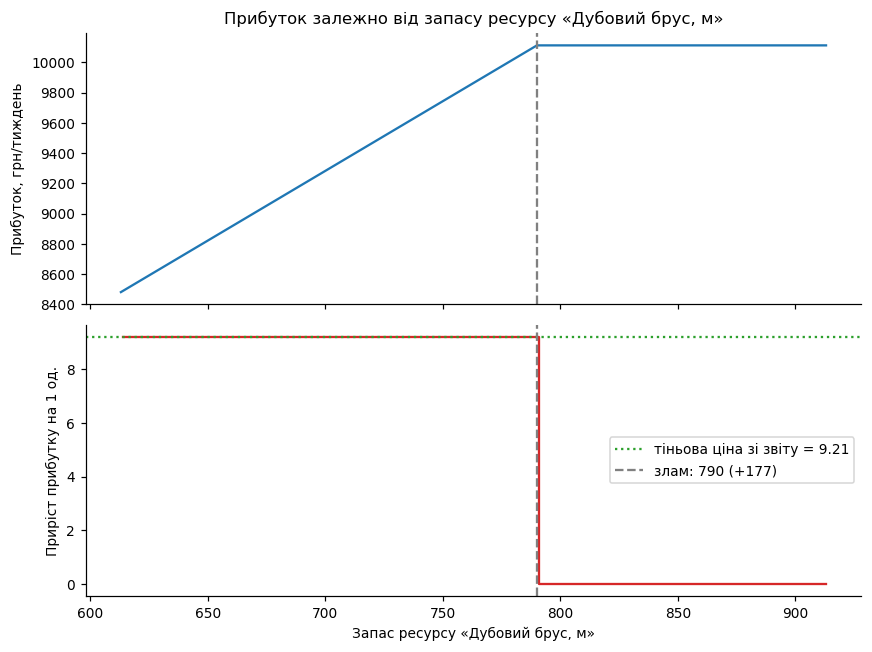

In [8]:
steps = np.arange(0, 301)                      # extra stock: 0, 1, ..., 300
profits = []
for d in steps:
    bb = b.copy(); bb[i_max] += d
    profits.append(-solve_lp(bb).fun)
profits = np.array(profits)
slope = np.diff(profits)                       # profit gain from each extra unit

# break point: first step where slope no longer equals the shadow price
breakpoint_ = int(np.argmax(~np.isclose(slope, shadow[i_max])))
print('Нахил дорівнює тіньовій ціні %.4f для перших %d одиниць' % (shadow[i_max], breakpoint_))
print('Після цього нахил = %.4f' % slope[breakpoint_])
print('Межа: запас %d -> %d м, прибуток %.2f -> %.2f'
      % (b[i_max], b[i_max] + breakpoint_, profits[0], profits[breakpoint_]))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
stock = b[i_max] + steps
ax1.plot(stock, profits, color='tab:blue')
ax1.axvline(b[i_max] + breakpoint_, ls='--', color='grey')
ax1.set_ylabel('Прибуток, грн/тиждень')
ax1.set_title('Прибуток залежно від запасу ресурсу «%s»' % resources[i_max])
ax2.step(stock[1:], slope, where='post', color='tab:red')
ax2.axhline(shadow[i_max], ls=':', color='tab:green',
            label='тіньова ціна зі звіту = %.2f' % shadow[i_max])
ax2.axvline(b[i_max] + breakpoint_, ls='--', color='grey',
            label='злам: %d (+%d)' % (b[i_max] + breakpoint_, breakpoint_))
ax2.set_xlabel('Запас ресурсу «%s»' % resources[i_max])
ax2.set_ylabel('Приріст прибутку на 1 од.')
ax2.legend(loc='center right')
plt.tight_layout(); plt.show()

**Відповідь 5.2:** нахил прибутку тримається рівно на рівні тіньової ціни 9,2143 для **177 додаткових метрів** бруса (запас від 613 до 790 м), після чого падає до **нуля**. Це точно збігається з «допустимим збільшенням» **177** у звіті Excel.

Чому межа саме 177: кожен додатковий метр бруса переводить план у бік крісел (+0,2143 шт.) за рахунок лав (−0,0714 шт.). Лав у плані 12,643, тож вони закінчуються через $12{,}643 / 0{,}0714 = 177$ м. Далі план — 158 крісел і нічого більше, і тепер вузьке місце — фанера ($2\cdot158 = 316$): додатковий брус уже нікуди витратити, його тіньова ціна стає 0. Тобто «допустиме збільшення» — це відстань до моменту, коли змінюється базис (набір виробів у плані), і разом з ним — тіньова ціна.

---
# Етап 6. Рішення про закупівлю

Постачальник пропонує вам додатковий обсяг ресурсу — див. блок «ПРОПОЗИЦІЯ
ПОСТАЧАЛЬНИКА» у ваших даних.

### Завдання 6.1
Дайте відповідь директорові на три питання, спираючись на числа, а не на здоровий глузд:

1. **Брати чи не брати?** Порівняйте ціну пропозиції з тіньовою ціною.
2. **Скільки саме брати?** Постачальник пропонує більше, ніж вам потрібно.
3. **Скільки на цьому заробимо?** Порахуйте виграш і перевірте його прямим
   розв'язанням задачі з новим запасом.

In [9]:
i_offer   = V['ресурс_пропозиції']
price     = V['ціна_пропозиції']
offer_qty = V['обсяг_пропозиції']
print('Пропозиція: %s, %.1f грн/од., до %d од.' % (resources[i_offer], price, offer_qty))
print('Тіньова ціна цього ресурсу: %.4f\n' % shadow[i_offer])

# marginal effect of each extra unit up to the full offered quantity
P = []
for d in range(offer_qty + 1):
    bb = b.copy(); bb[i_offer] += d
    P.append(-solve_lp(bb).fun)
P = np.array(P)
marginal = np.diff(P)                              # what the d-th unit adds
buy_qty = int(np.sum(marginal > price + 1e-9))     # buy while a unit earns more than it costs

def purchase_effect(q):
    bb = b.copy(); bb[i_offer] += q
    r = solve_lp(bb)
    gain_ = -r.fun - profit
    cost_ = q * price
    return r.x, -r.fun, gain_, cost_, gain_ - cost_

rows = {}
for label, q in [('нічого не купувати', 0), ('купити %d (оптимум)' % buy_qty, buy_qty),
                 ('купити весь обсяг %d' % offer_qty, offer_qty)]:
    x_, p_, g_, cost_, net_ = purchase_effect(q)
    rows[label] = {'план': np.round(x_, 3), 'прибуток': round(p_, 2), 'приріст прибутку': round(g_, 2),
                   'витрати на закупівлю': round(cost_, 2), 'чистий виграш': round(net_, 2)}
print(pd.DataFrame(rows).T.to_string())

forecast = buy_qty * (shadow[i_offer] - price)
print('\nПрогноз за звітом: %d × (%.4f − %.1f) = %.2f грн' % (buy_qty, shadow[i_offer], price, forecast))
print('Пряме розв\'язання:                     %.2f грн' % purchase_effect(buy_qty)[4])

Пропозиція: Дубовий брус, м, 5.4 грн/од., до 354 од.
Тіньова ціна цього ресурсу: 9.2143

                                              план прибуток приріст прибутку витрати на закупівлю чистий виграш
нічого не купувати     [120.071, 0.0, 0.0, 12.643]  8481.07              0.0                  0.0           0.0
купити 177 (оптимум)        [158.0, 0.0, 0.0, 0.0]  10112.0          1630.93                955.8        675.13
купити весь обсяг 354       [158.0, 0.0, 0.0, 0.0]  10112.0          1630.93               1911.6       -280.67

Прогноз за звітом: 177 × (9.2143 − 5.4) = 675.13 грн
Пряме розв'язання:                     675.13 грн


**Відповідь 6.1:**

* **Брати чи ні і чому:** **брати.** Постачальник пропонує дубовий брус по **5,4 грн/м**, а тіньова ціна бруса — **9,21 грн/м**: кожен куплений метр (у межах діапазону) приносить 9,21 грн додаткового прибутку і коштує 5,4 — чистий плюс 3,81 грн з метра. Купувати ресурс з нульовою тіньовою ціною не було б сенсу за будь-яку ціну.
* **Скільки одиниць має сенс купити і чому не більше:** **177 м, а не всі 354.** Тіньова ціна 9,21 діє лише в межах допустимого збільшення 177 (перевірено на етапі 5.2). Після 177 м лави зникають з плану, вузьким місцем стає фанера, і тіньова ціна бруса падає до 0 — кожен наступний метр коштує 5,4 грн і не дає нічого. Решту 177 м ми б купили, щоб вони лежали на складі.
* **Очікуваний виграш:** приріст прибутку $177 \cdot 9{,}2143 = 1630{,}93$ грн, витрати $177 \cdot 5{,}4 = 955{,}80$ грн, **чистий виграш ≈ 675,13 грн/тиждень**.
* **Перевірка прямим розв'язанням дала:** із запасом бруса 790 м оптимальний план — 158 крісел, прибуток 10 112 грн (було 8481,07), приріст 1630,93, мінус закупівля 955,80 = **675,13 грн** — збігається з прогнозом. Для порівняння: якщо купити весь обсяг 354 м, прибуток той самий (10 112), а витрати 1911,60 — **чистий результат −280,67 грн**, тобто збиток відносно варіанта «нічого не купувати».

Зауваження для директора: після закупівлі план стає «вироджений» — випускаємо лише крісла, і брус, і фанера витрачаються повністю. Наступне вузьке місце — фанера; якщо будуть пропозиції щодо неї, їх треба оцінювати вже за новим звітом.

---
# Етап 7. Перевірка розв'язку

### Завдання 7.1
Порахуйте дві величини:

* скільки виробів мають **ненульовий** випуск;
* скільки обмежень **зв'язні** (ресурс витрачено повністю).

Порівняйте.

In [10]:
eps = 1e-6
n_nonzero = int(np.sum(plan > eps))
n_binding = int(np.sum(slack < eps))
print('Ненульові змінні:', [products[j] for j in range(4) if plan[j] > eps])
print('Зв’язні обмеження:', [resources[i] for i in range(5) if slack[i] < eps])

# names required by the template's check cells (do not remove)
ненульових, звязних = n_nonzero, n_binding

Ненульові змінні: ['Крісло', 'Лава']
Зв’язні обмеження: ['Дубовий брус, м', 'Фанера, м²']


In [11]:
assert ненульових is not None and звязних is not None, 'спершу порахуйте'
print('ненульових змінних: %s | зв’язних обмежень: %s' % (ненульових, звязних))
assert ненульових == звязних, ('числа не збіглися — це сигнал. Перевірте розв’язок '
                               'і поясніть причину в клітинці нижче')
print('Етап 7 пройдено')

ненульових змінних: 2 | зв’язних обмежень: 2
Етап 7 пройдено


**Відповідь 7.1:** числа збіглися: **2 ненульові змінні** (Крісло, Лава) і **2 зв'язні обмеження** (брус, фанера).

Чому так має бути: оптимальний розв'язок лінійної задачі лежить у вершині допустимої області. Два ненульові випуски визначаються саме двома рівняннями — двома вичерпаними ресурсами: $5x_1 + x_4 = 613$, $2x_1 + 6x_4 = 316$, звідки $x_1 = 120{,}07$, $x_4 = 12{,}64$. Кожен зв'язний ресурс «тримає» один виріб у плані.

Що означала б розбіжність:
* **зв'язних більше, ніж ненульових** — розв'язок **вироджений**: у вершині перетинається більше обмежень, ніж треба. Тоді тіньові ціни неоднозначні (Excel покаже одну з можливих), а допустимі збільшення/зменшення можуть бути нульовими — звіту треба довіряти обережно. Ми побачили це на етапі 6: після закупівлі 177 м бруса в плані лише 1 виріб (крісла), а вичерпано 2 ресурси.
* **ненульових більше, ніж зв'язних** — розв'язувач повернув не вершину, а точку на ребрі між оптимальними вершинами (є **альтернативні оптимуми**; одна зі зведених вартостей невиробних виробів дорівнювала б 0) — або це ознака помилки в моделі чи в розв'язку.

---
# Етап 8. Цілочисельність

Ваш оптимальний план містить дробові числа. Виготовити 63,3 виробу неможливо.

### Завдання 8.1
Порівняйте три варіанти:

1. розв'язок без умови цілочисельності (уже маєте);
2. **округлений** план — округліть кожне значення до цілого й перевірте, чи він
   узагалі допустимий і скільки прибутку дає;
3. справжній **цілочисельний** оптимум — розв'яжіть задачу з умовою, що всі змінні цілі
   (`cat='Integer'` у PuLP або `integrality=1` у `linprog`).

In [12]:
# 1) without integrality — already have: plan, profit
# 2) rounded plan
plan_round = np.round(plan)
usage_round = A @ plan_round
round_feasible = bool(np.all(usage_round <= b + 1e-9))
print('Округлений план:', plan_round, '| прибуток', c @ plan_round)
print(pd.DataFrame({'витрата': usage_round, 'запас': b, 'вистачає?': usage_round <= b},
                   index=resources).to_string())

# 3) true integer optimum
res_int = solve_lp(integer=True)
plan_int, profit_int = np.round(res_int.x), -res_int.fun
print('\nЦілочисельний оптимум:', plan_int, '| прибуток', profit_int,
      '| допустимий:', bool(np.all(A @ plan_int <= b)))

comparison = pd.DataFrame({
    'план': [np.round(plan, 3), plan_round, plan_int],
    'прибуток': [round(profit, 2), c @ plan_round, profit_int],
    'допустимий?': [True, round_feasible, True]},
    index=['без цілочисельності', 'округлений', 'цілочисельний оптимум'])
print(); print(comparison.to_string())

Округлений план: [120.   0.   0.  13.] | прибуток 8499.0
                   витрата   запас  вистачає?
Дубовий брус, м      613.0   613.0       True
Фанера, м²           318.0   316.0      False
Фурнітура, компл.    360.0  1035.0       True
Верстат, год          78.0   739.0       True
Лакування, год       318.0   810.0       True

Цілочисельний оптимум: [120.   0.   0.  12.] | прибуток 8436.0 | допустимий: True

                                              план  прибуток  допустимий?
без цілочисельності    [120.071, 0.0, 0.0, 12.643]   8481.07         True
округлений                 [120.0, 0.0, 0.0, 13.0]   8499.00        False
цілочисельний оптимум      [120.0, 0.0, 0.0, 12.0]   8436.00         True


**Відповідь 8.1:**

| Варіант | План (Крісло, Стілець, Табурет, Лава) | Прибуток | Допустимий? |
|---|---|---|---|
| без умови цілочисельності | 120,071; 0; 0; 12,643 | 8481,07 | так (але дробовий) |
| округлений | 120; 0; 0; 13 | 8499 | **ні** — фанери треба $2\cdot120 + 6\cdot13 = 318 > 316$ |
| цілочисельний оптимум | 120; 0; 0; 12 | 8436 | так |

**Висновок:** округлювати не можна. Округлений план виглядає навіть «вигіднішим» за оптимальний (8499 > 8481) — і саме це мало б насторожити: прибуток, більший за оптимум LP, неможливий для допустимого плану. Лава округлилася вгору (12,64 → 13), а фанера — дефіцитний ресурс, витрачений до останнього м², тож для 13-ї лави її просто немає (бракує 2 м²). Округлення в будь-який бік не враховує обмежень; у дефіцитних ресурсах округлення вгору майже завжди їх порушує. Правильний шлях — розв'язати задачу з умовою цілочисельності (метод гілок і меж): 120 крісел і 12 лав, 8436 грн. Втрата від цілочисельності — 45,07 грн (0,5 %), а оцінка LP (8481) є верхньою межею для будь-якого цілого плану.

---
# ЧАСТИНА 2. Транспортна задача

Друга частина виконується самостійно. Тут ви застосуєте ту саму методику до задачі
іншого класу — і побачите, що вона поводиться інакше.

# Етап 9. Ваші дані

### Завдання 9.1
Сформуйте власні дані:

* **три міста-постачальники** — за першими трьома літерами вашого **прізвища**;
* **чотири міста-споживачі** — за першими чотирма літерами вашого **імені**;
* **матриця відстаней 3 × 4** — реальні відстані автошляхами за Google Maps, у кілометрах;
* **запаси і попит** — невеликі цілі числа, підберіть так, щоб **сумарний запас
  дорівнював сумарному попиту**.

> Якщо на якусь літеру міста немає — беріть наступну літеру прізвища чи імені.
> Якщо сумарний запас не дорівнює попиту, задача з обмеженнями-рівностями
> **не матиме розв'язку взагалі**. Це не помилка Python — це властивість моделі.

In [13]:
# Surname ЦИМбалюк: no Ukrainian cities on «Ц» and «И» -> next letters М, Б, А
# First name АНТОн: А, Н, Т, О
suppliers = ['Миколаїв', 'Біла Церква', 'Ананьїв']
consumers = ['Арциз', 'Ніжин', 'Тернопіль', 'Одеса']
# road distances, km (Google Maps, shortest suggested route)
D = np.array([[318, 615, 655, 132],      # Миколаїв
              [580, 225, 415, 395],      # Біла Церква
              [350, 525, 500, 170]],     # Ананьїв
             float)
supply = [35, 25, 20]                    # total 80
demand = [17, 21, 19, 23]                # total 80

# names required by the template's check cells (do not remove)
постачальники, споживачі, запас, попит = suppliers, consumers, supply, demand

assert len(постачальники) == 3 and len(споживачі) == 4, 'потрібно 3 постачальники і 4 споживачі'
assert D.shape == (3, 4), 'матриця відстаней має бути 3 x 4'
assert sum(запас) == sum(попит), 'сумарний запас має дорівнювати сумарному попиту'
pd.DataFrame(D, index=постачальники, columns=споживачі)

,Арциз,Ніжин,Тернопіль,Одеса
Миколаїв,318.0,615.0,655.0,132.0
Біла Церква,580.0,225.0,415.0,395.0
Ананьїв,350.0,525.0,500.0,170.0


---
# Етап 10. Розв'язання транспортної задачі

### Завдання 10.1
Розв'яжіть задачу **двічі різними засобами**: наприклад `pulp` і
`scipy.optimize.linprog(method='highs')`. Обмеження — рівності.

Для кожного розв'язку виведіть: оптимальний план перевезень, сумарну вартість
і **тіньові ціни всіх обмежень**.

In [14]:
# Solution 1: PuLP (CBC solver)
m, n = D.shape
assert HAS_PULP, 'Solution 1 needs pulp: pip install "pulp<4"'
tp = pulp.LpProblem('transport', pulp.LpMinimize)
X = {(i, j): pulp.LpVariable('x_%d_%d' % (i, j), lowBound=0) for i in range(m) for j in range(n)}
tp += pulp.lpSum(D[i, j] * X[i, j] for i in range(m) for j in range(n))
for i in range(m):
    tp += pulp.lpSum(X[i, j] for j in range(n)) == supply[i], 'S%d' % i
for j in range(n):
    tp += pulp.lpSum(X[i, j] for i in range(m)) == demand[j], 'C%d' % j
tp.solve(pulp.PULP_CBC_CMD(msg=0))

plan1 = np.array([[X[i, j].value() for j in range(n)] for i in range(m)])
cost1 = pulp.value(tp.objective)
u1 = np.array([tp.constraints['S%d' % i].pi for i in range(m)])   # supplier shadow prices
v1 = np.array([tp.constraints['C%d' % j].pi for j in range(n)])   # consumer shadow prices

print('PuLP / CBC, статус:', pulp.LpStatus[tp.status])
print(pd.DataFrame(plan1, index=suppliers, columns=consumers).to_string())
print('Сумарна вартість (т·км): %.0f' % cost1)
print('Тіньові ціни постачальників u:', dict(zip(suppliers, u1.round(4).tolist())))
print('Тіньові ціни споживачів    v:', dict(zip(consumers, v1.round(4).tolist())))

PuLP / CBC, статус: Optimal
             Арциз  Ніжин  Тернопіль  Одеса
Миколаїв      12.0    0.0        0.0   23.0
Біла Церква    0.0   21.0        4.0    0.0
Ананьїв        5.0    0.0       15.0    0.0
Сумарна вартість (т·км): 22487
Тіньові ціни постачальників u: {'Миколаїв': 278.0, 'Біла Церква': 225.0, 'Ананьїв': 310.0}
Тіньові ціни споживачів    v: {'Арциз': 40.0, 'Ніжин': 0.0, 'Тернопіль': 190.0, 'Одеса': -146.0}


In [15]:
# Solution 2: scipy.optimize.linprog (HiGHS)
A_eq = np.zeros((m + n, m * n))
for i in range(m):
    for j in range(n):
        A_eq[i, i * n + j] = 1          # row i: everything shipped from supplier i
        A_eq[m + j, i * n + j] = 1      # row m+j: everything delivered to consumer j
res2 = linprog(D.ravel(), A_eq=A_eq, b_eq=supply + demand, bounds=(0, None), method='highs')
assert res2.status == 0, res2.message

plan2 = res2.x.reshape(m, n)
cost2 = res2.fun
u2 = res2.eqlin.marginals[:m] + 0.0    # +0.0 removes "-0"
v2 = res2.eqlin.marginals[m:] + 0.0

print('linprog / HiGHS:', res2.message)
print(pd.DataFrame(plan2, index=suppliers, columns=consumers).to_string())
print('Сумарна вартість (т·км): %.0f' % cost2)
print('Тіньові ціни постачальників u:', dict(zip(suppliers, u2.round(4).tolist())))
print('Тіньові ціни споживачів    v:', dict(zip(consumers, v2.round(4).tolist())))

linprog / HiGHS: Optimization terminated successfully. (HiGHS Status 7: Optimal)
             Арциз  Ніжин  Тернопіль  Одеса
Миколаїв      12.0    0.0        0.0   23.0
Біла Церква    0.0   21.0        4.0    0.0
Ананьїв        5.0    0.0       15.0    0.0
Сумарна вартість (т·км): 22487
Тіньові ціни постачальників u: {'Миколаїв': 0.0, 'Біла Церква': -53.0, 'Ананьїв': 32.0}
Тіньові ціни споживачів    v: {'Арциз': 318.0, 'Ніжин': 278.0, 'Тернопіль': 468.0, 'Одеса': 132.0}


### Завдання 10.2 — головне питання цієї частини
Порівняйте два набори тіньових цін.

**Сумарна вартість у двох розв'язувачів однакова. А тіньові ціни?**

Якщо вони різні — це не помилка. Знайдіть закономірність: подивіться на різницю
між відповідними значеннями окремо для постачальників і окремо для споживачів.

In [16]:
duals = pd.DataFrame({
    'PuLP': np.r_[u1, v1], 'linprog': np.r_[u2, v2]},
    index=['u: ' + s for s in suppliers] + ['v: ' + s for s in consumers])
duals['різниця PuLP − linprog'] = duals['PuLP'] - duals['linprog']
print('Вартість: PuLP %.0f, linprog %.0f, однакова: %s' % (cost1, cost2, np.isclose(cost1, cost2)))
print('Плани однакові:', np.allclose(plan1, plan2))
print(); print(duals.to_string())

k = u1[0] - u2[0]
print('\nРізниця для всіх постачальників = %+.0f, для всіх споживачів = %+.0f' % (k, -k))
print('u1 = u2 + k:', np.allclose(u1, u2 + k), '|  v1 = v2 − k:', np.allclose(v1, v2 - k))

# for every route u_i + v_j is the same in both reports — that is the meaningful quantity
uv1 = u1[:, None] + v1[None, :]
uv2 = u2[:, None] + v2[None, :]
used = plan2 > 1e-9
print('\nu_i + v_j (PuLP) == u_i + v_j (linprog):', np.allclose(uv1, uv2))
print('Для зайнятих маршрутів u_i + v_j = відстань:', np.allclose(uv2[used], D[used]))
print('Для вільних маршрутів  u_i + v_j <= відстань:', bool(np.all(uv2 <= D + 1e-9)))

Вартість: PuLP 22487, linprog 22487, однакова: True
Плани однакові: True

                 PuLP  linprog  різниця PuLP − linprog
u: Миколаїв     278.0      0.0                   278.0
u: Біла Церква  225.0    -53.0                   278.0
u: Ананьїв      310.0     32.0                   278.0
v: Арциз         40.0    318.0                  -278.0
v: Ніжин          0.0    278.0                  -278.0
v: Тернопіль    190.0    468.0                  -278.0
v: Одеса       -146.0    132.0                  -278.0

Різниця для всіх постачальників = +278, для всіх споживачів = -278
u1 = u2 + k: True |  v1 = v2 − k: True

u_i + v_j (PuLP) == u_i + v_j (linprog): True
Для зайнятих маршрутів u_i + v_j = відстань: True
Для вільних маршрутів  u_i + v_j <= відстань: True


**Відповідь 10.2:**

* **Вартість у двох розв'язувачів:** однакова — **22 487 т·км**; плани перевезень теж збіглися.
* **Тіньові ціни збіглися чи ні:** **ні.** PuLP: $u = (278,\ 225,\ 310)$, $v = (40,\ 0,\ 190,\ -146)$; linprog: $u = (0,\ -53,\ 32)$, $v = (318,\ 278,\ 468,\ 132)$.
* **Яку закономірність ви побачили в різниці:** різниця **стала**: для всіх постачальників $u^{PuLP}_i - u^{linprog}_i = +278$, для всіх споживачів $v^{PuLP}_j - v^{linprog}_j = -278$. Тобто один набір отримано з іншого зсувом $u_i + k,\ v_j - k$. Причина — у транспортній задачі з балансом обмеження лінійно залежні: сума всіх рівнянь постачальників дорівнює сумі всіх рівнянь споживачів (обидві = 80). Незалежних обмежень лише $3 + 4 - 1 = 6$, а тіньових цін 7, тому двоїста задача має **безліч оптимальних розв'язків** — одна ступінь свободи. Будь-який зсув на $k$ не змінює ні двоїстої цільової функції ($k\sum a_i - k\sum b_j = 0$), ні умов $u_i + v_j \le d_{ij}$. HiGHS фактично «прив'язав» $u_\text{Миколаїв} = 0$, CBC — $v_\text{Ніжин} = 0$. **Правильні обидві відповіді**, жодна не «справжня».
* **Що це означає для того, хто збирається ухвалювати рішення за цим звітом:** окрему тіньову ціну тут **не можна читати** як «скільки коштує ще одна одиниця запасу в Миколаєві» — це число довільне (0 чи 278 залежить від розв'язувача), і навіть знак у нього довільний (у linprog $u_\text{Біла Церква} = -53$, у PuLP $+225$). До того ж збільшити лише один запас неможливо — порушиться баланс, і задача стане недопустимою. Змістовні лише **комбінації** $u_i + v_j$ — гранична вартість перевезення ще однієї одиниці від постачальника $i$ до споживача $j$ (вона однакова в обох звітах, і для зайнятих маршрутів дорівнює відстані), та різниці всередині однієї групи (наприклад, $u_\text{Ананьїв} - u_\text{Миколаїв} = 32$ в обох звітах). Методика етапу 6 «порівняй ціну з тіньовою ціною» тут у лоб не працює.

---
# Етап 11. Перевірка розв'язку — і чому вона тут не працює

### Завдання 11.1
Порахуйте для транспортної задачі те саме, що на етапі 7:

* кількість **ненульових перевезень**;
* кількість **зв'язних обмежень**.

Порівняйте з числом `3 + 4 = 7` — кількістю обмежень у задачі.

In [17]:
eps = 1e-9
n_routes = int(np.sum(plan2 > eps))
shipped, received = plan2.sum(axis=1), plan2.sum(axis=0)
n_binding_tp = int(np.sum(np.isclose(shipped, supply)) + np.sum(np.isclose(received, demand)))
print('Ненульових перевезень: %d із %d' % (n_routes, m * n))
print('Зв’язних обмежень:     %d із %d' % (n_binding_tp, m + n))
print('m + n − 1 = %d' % (m + n - 1))
print('Ранг матриці обмежень A_eq = %d (а рядків %d)' % (np.linalg.matrix_rank(A_eq), m + n))

Ненульових перевезень: 6 із 12
Зв’язних обмежень:     7 із 7
m + n − 1 = 6
Ранг матриці обмежень A_eq = 6 (а рядків 7)


**Відповідь 11.1:**

* **Ненульових перевезень:** 6 (з 12 можливих маршрутів): Миколаїв→Арциз 12, Миколаїв→Одеса 23, Біла Церква→Ніжин 21, Біла Церква→Тернопіль 4, Ананьїв→Арциз 5, Ананьїв→Тернопіль 15.
* **Зв'язних обмежень:** 7 — тобто всі.
* **Чому в транспортній задачі зв'язними виявляються всі обмеження:** вони задані **рівностями** — будь-який допустимий план вивозить увесь запас і задовольняє весь попит. «Залишку» не може бути за означенням, тож рівність «зв'язне = вичерпане» тут нічого не говорить про дефіцитність. Тому й перевірка етапу 7 «ненульових = зв'язних» тут не працює.
* **На скільки ненульових перевезень менше і чому саме на стільки:** на **одне** — $6 = 3 + 4 - 1$. З 7 рівнянь одне є наслідком інших (сума запасів = сума попиту, ранг матриці обмежень — 6). Базисний (вершинний) розв'язок містить стільки базисних змінних, скільки незалежних обмежень, тобто $m + n - 1 = 6$. Якби ненульових було менше за 6 — план вироджений (трапляється, коли часткова сума запасів дорівнює частковій сумі попиту; запаси 35/25/20 і попит 17/21/19/23 підібрано так, щоб такого збігу не було). Ця ж залежність обмежень — причина неоднозначності тіньових цін з етапу 10.

### Завдання 11.2 — візуалізація
Побудуйте дві теплові карти поруч: матрицю відстаней і матрицю оптимальних перевезень.
Підпишіть осі та значення в комірках.

*За бажанням (не оцінюється): граф маршрутів через `networkx`, де товщина ребра
пропорційна обсягу перевезення.*

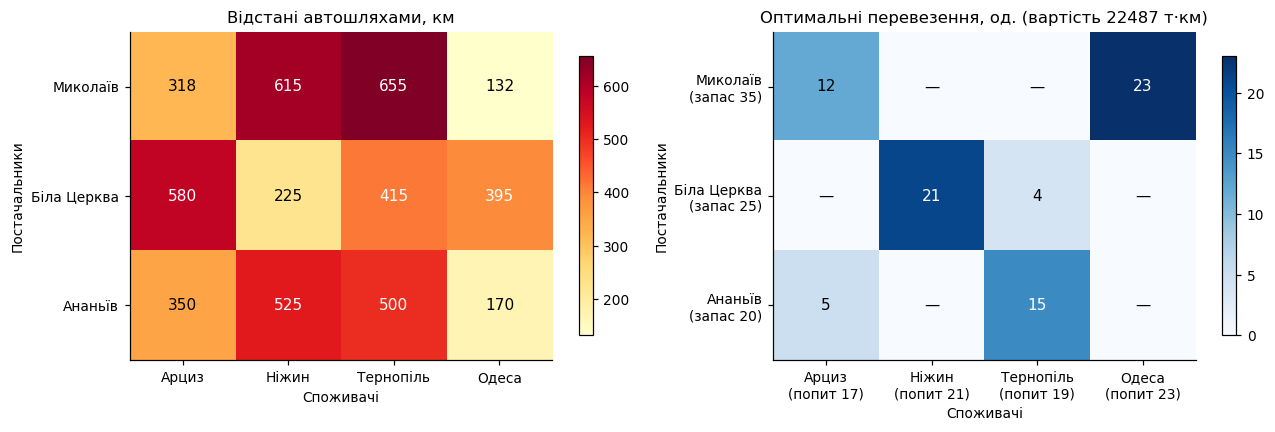

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
panels = [(axes[0], D, 'Відстані автошляхами, км', 'YlOrRd'),
          (axes[1], plan2, 'Оптимальні перевезення, од. (вартість %.0f т·км)' % cost2, 'Blues')]
for ax, mat, title, cmap in panels:
    im = ax.imshow(mat, cmap=cmap, aspect='auto')
    ax.set_xticks(range(n)); ax.set_xticklabels(consumers)
    ax.set_yticks(range(m)); ax.set_yticklabels(suppliers)
    ax.set_xlabel('Споживачі'); ax.set_ylabel('Постачальники'); ax.set_title(title)
    for i in range(m):
        for j in range(n):
            val = mat[i, j]
            ax.text(j, i, '%.0f' % val if val > 1e-9 else '—', ha='center', va='center',
                    color='white' if val > mat.max() * 0.6 else 'black', fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.85)
# supply / demand in tick labels
axes[1].set_yticklabels(['%s\n(запас %d)' % (s, q) for s, q in zip(suppliers, supply)])
axes[1].set_xticklabels(['%s\n(попит %d)' % (s, q) for s, q in zip(consumers, demand)])
plt.tight_layout(); plt.show()

**Висновок:** перевезення зосереджені на найкоротших маршрутах кожного постачальника (Миколаїв→Одеса 132 км, Біла Церква→Ніжин 225 км), а там, де найкоротшого не вистачає, оптимум обирає не найдешевший маршрут окремо, а найменшу «втрату» для всієї системи: Тернопіль, найдальший від усіх, отримує вантаж з Ананьєва та Білої Церкви, а Ананьїв везе в Арциз, хоча Одеса йому ближча — бо Одесу дешевше закрити з Миколаєва.

---
# Етап 12. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями **дозволено**. Обов'язковою є прозорість.
Порушенням є не використання інструмента, а нездатність пояснити власний код
і власні числа на захисті.

Для кожного етапу оберіть одне: `'ні'`, `'синтаксис'`, `'код, перевірено'`,
`'текст, перероблено'`, `'текст, як є'`.

In [21]:
ІНСТРУМЕНТИ_ШІ = 'Claude'

# Значення відображають, як робота була зроблена: код і текст згенеровано мовною моделлю.
# Після того, як ви перепишете висновки своїми словами, змініть 'текст, як є' на 'текст, перероблено'.
ДЕКЛАРАЦІЯ = {
    'етап 1, формалізація моделі':          'текст, як є',
    'етап 2, побудова моделі в Excel':      'код, перевірено',
    'етап 3, код на Python':                'код, перевірено',
    'етапи 4–5, читання та перевірка звіту': 'текст, як є',
    'етап 6, рішення про закупівлю':        'текст, як є',
    'етапи 7–8, перевірка та цілочисельність': 'текст, як є',
    'етапи 9–11, транспортна задача':       'текст, як є',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно.
# ЗАМІНІТЬ на те, що ви перевірили САМІ. Нижче — перелік перевірок, які варто зробити:
ЩО_ПЕРЕВІРЕНО = ('Звірив план і прибуток Python (120,07 крісел, 12,64 лави, 8481,07) з Excel Solver; '
                 'вручну перерахував зведену вартість стільця 58 - (3*9,2143 + 5*8,9643) = -14,46; '
                 'перевірив, що округлений план (120; 0; 0; 13) потребує 318 м² фанери при запасі 316; '
                 'перевірив, що тіньові ціни PuLP і linprog відрізняються на сталу +278/-278, а суми u_i+v_j збігаються.')

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-яке число
# цієї роботи та внести зміни в модель на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True   # встановіть True САМІ — лише коли це справді так

In [22]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}
assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше (зараз %d символів, '
                                           'потрібно щонайменше 120)' % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'
print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-42s %s' % ('автор:', ПІБ))
print('%-42s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-42s %s' % (k + ':', v))
print('-' * 78)
print(ЩО_ПЕРЕВІРЕНО)

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                     Цимбалюк Антон Едуардович
інструменти:                               Claude
------------------------------------------------------------------------------
етап 1, формалізація моделі:               текст, як є
етап 2, побудова моделі в Excel:           код, перевірено
етап 3, код на Python:                     код, перевірено
етапи 4–5, читання та перевірка звіту:     текст, як є
етап 6, рішення про закупівлю:             текст, як є
етапи 7–8, перевірка та цілочисельність:   текст, як є
етапи 9–11, транспортна задача:            текст, як є
------------------------------------------------------------------------------
Звірив план і прибуток Python (120,07 крісел, 12,64 лави, 8481,07) з Excel Solver; вручну перерахував зведену вартість стільця 58 - (3*9,2143 + 5*8,9643) = -14,46; перевірив, що округлений план (120; 0; 0; 13) потребує 318 м² фанери при запасі 316; перевірив, що тіньові ціни PuLP і lin

---
# Крок 13. Фінальна самоперевірка

In [23]:
перевірки = {
    'ПІБ і варіант заповнено':            bool(ПІБ) and 1 <= ВАРІАНТ <= 30,
    'Excel і Python дали однаковий план': abs(прибуток - EXCEL_ПРИБУТОК) < 0.5,
    'перевірку «ненульові = зв’язні» зроблено': ненульових == звязних,
    'дані транспортної задачі введено':   len(постачальники) == 3 and len(споживачі) == 4,
    'баланс запасів і попиту':            sum(запас) == sum(попит),
    'декларацію заповнено':               bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)
if all(перевірки.values()):
    print('\nТехнічна частина виконана.')
    print('Переконайтеся, що заповнені ВСІ клітинки з відповідями,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     Excel і Python дали однаковий план
OK     перевірку «ненульові = зв’язні» зроблено
OK     дані транспортної задачі введено
OK     баланс запасів і попиту
OK     декларацію заповнено

Технічна частина виконана.
Переконайтеся, що заповнені ВСІ клітинки з відповідями,
і виконайте Kernel → Restart & Run All перед здачею.
